# Notebook 02: Giai đoạn 1 — Khôi phục vùng cháy sáng hồng & Khử nhiễu lai đa miền Wavelet + Non-Local Means (Chương 2, 3, 4 & 6)
**Phụ trách:** Thành viên 1 (Nhóm trưởng)

### Cơ sở toán học & Lý do chọn tham số:
1. **Mặt nạ nội suy mềm vùng cháy sáng hồng $\alpha(x,y) \in [0, 1]$ (Chương 2 & 4):**
   $$RB_{\text{mean}}(x,y) = \frac{R(x,y) + B(x,y)}{2}, \quad D_{\text{pink}}(x,y) = \max(0, RB_{\text{mean}}(x,y) - G(x,y))$$
   $$\alpha(x,y) = G_{7\times 7, \sigma=1.5} * \left( \text{clip}\left(\frac{RB_{\text{mean}} - 135.0}{40.0}, 0, 1\right) \cdot \text{clip}\left(\frac{D_{\text{pink}} - 7.0}{16.0}, 0, 1\right) \right)$$
2. **Cân bằng trắng tự động có mặt nạ (Masked Gray World AWB - Chương 4):** Loại trừ vùng bão hòa ($\alpha(x,y) \ge 0.20$, $Y \notin (30, 215)$) với biên độ dịch chuyển tối đa $\pm 6\%$.
3. **Khử nhiễu lai đa miền (Chương 3 & 6):** Phân rã Wavelet `sym4` 3 mức ngưỡng mềm `BayesShrink` trên YCbCr kết hợp `fastNlMeansDenoising` ($h=4.5$) có mặt nạ bảo vệ tán lá cây trên $L^*$ và lọc Median $3\times3$ + Bilateral ($d=5, \sigma_{\text{color}}=14, \sigma_{\text{space}}=7$) trên $a^*, b^*$.

Pink Cast Index trước xử lý: 32.53%
Pink Cast Index sau Giai đoạn 1: 1.14%


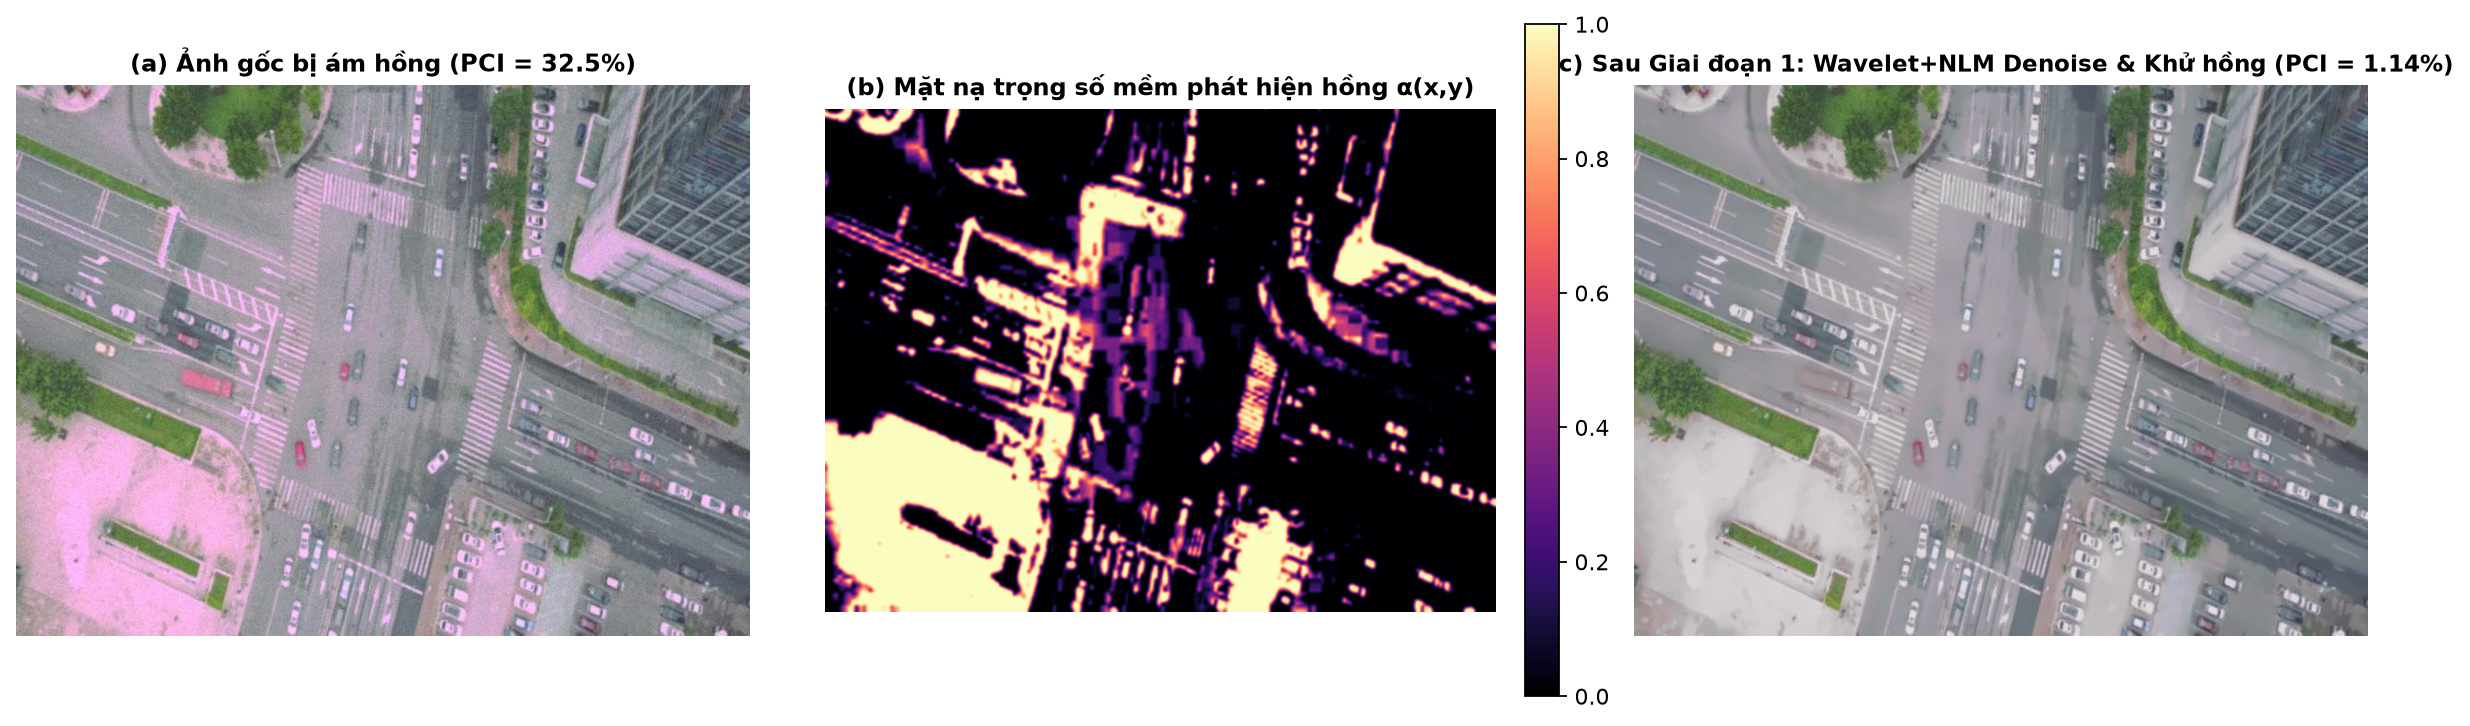

In [1]:
import sys, cv2
import matplotlib.pyplot as plt
sys.path.insert(0, "/home/ngtukien/Projects/XLA")
from src.uav_pipeline import run_stage1_preprocess, compute_pink_cast_index

img_in = cv2.imread("/home/ngtukien/Projects/XLA/data/samples/sample_real_sky_pink.jpg")
img_s1, alpha_mask = run_stage1_preprocess(img_in)
print(f"Pink Cast Index trước xử lý: {compute_pink_cast_index(img_in):.2f}%")
print(f"Pink Cast Index sau Giai đoạn 1: {compute_pink_cast_index(img_s1):.2f}%")